Call price: 4.3576
Put price:  3.6104
Delta: 0.5497 Gamma: 0.0396 Vega: 0.1979
Parity check: 0.7472 vs 0.7472
Monte Carlo call: 4.3627 +/- 0.0144   Formula: 4.3576

Experiment A: more rebalancing means less risk (true vol = priced vol)
   4 rebalances: mean P&L =  -0.010, std dev = 1.626
  16 rebalances: mean P&L =  -0.002, std dev = 0.863
  63 rebalances: mean P&L =  -0.010, std dev = 0.436
 252 rebalances: mean P&L =  -0.003, std dev = 0.219

Experiment B: what if the true volatility differs from the one you priced with?
True vol 0.15: mean P&L =   0.993, std dev = 0.458
True vol 0.20: mean P&L =  -0.000, std dev = 0.432
True vol 0.25: mean P&L =  -0.997, std dev = 0.693
True vol 0.30: mean P&L =  -1.996, std dev = 1.129


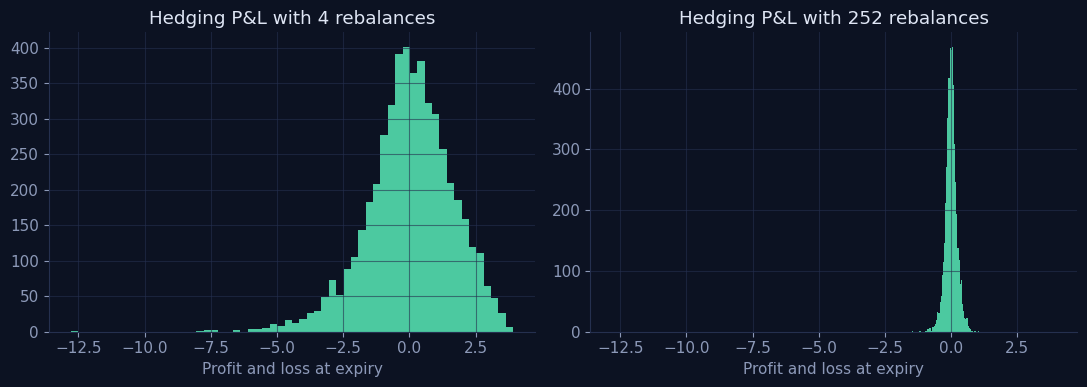

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#0c1222", "axes.facecolor": "#0c1222", "savefig.facecolor": "#0c1222",
    "axes.edgecolor": "#25304f", "axes.labelcolor": "#8c99b8",
    "xtick.color": "#8c99b8", "ytick.color": "#8c99b8", "text.color": "#dfe6f5",
    "axes.grid": True, "grid.color": "#25304f", "grid.alpha": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#4cc9a0", "#f2b84b", "#8b7cf6", "#f0707a"]),
    "font.size": 11,
})
from scipy.stats import norm
import plotly.graph_objects as go

np.random.seed(42)


S0 = 100.0      # starting stock price
K = 100.0       # strike price
T = 0.25        # time to expiry in years (about 3 months)
r = 0.03        # interest rate
SIGMA = 0.20    # volatility used for pricing and hedging

#formula and Greeks ----------
def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)

def bs_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_put(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def delta_call(S, K, T, r, sigma):
    d1, _ = d1_d2(S, K, T, r, sigma)
    return norm.cdf(d1)

def gamma(S, K, T, r, sigma):
    d1, _ = d1_d2(S, K, T, r, sigma)
    return norm.pdf(d1) / (S * sigma * np.sqrt(T))

def vega(S, K, T, r, sigma):
    d1, _ = d1_d2(S, K, T, r, sigma)
    return S * norm.pdf(d1) * np.sqrt(T) / 100   # per 1 percentage point of volatility

print("Call price:", round(bs_call(S0, K, T, r, SIGMA), 4))
print("Put price: ", round(bs_put(S0, K, T, r, SIGMA), 4))
print("Delta:", round(delta_call(S0, K, T, r, SIGMA), 4),
      "Gamma:", round(gamma(S0, K, T, r, SIGMA), 4),
      "Vega:", round(vega(S0, K, T, r, SIGMA), 4))

# Sanity check: put-call parity says call - put = S - K*exp(-rT)
print("Parity check:", round(bs_call(S0, K, T, r, SIGMA) - bs_put(S0, K, T, r, SIGMA), 4),
      "vs", round(S0 - K * np.exp(-r * T), 4))

#Monte Carlo price
def mc_call(S0, K, T, r, sigma, n=200_000):
    Z = np.random.randn(n)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoff = np.maximum(ST - K, 0) * np.exp(-r * T)
    return payoff.mean(), payoff.std() / np.sqrt(n)    # price and its standard error

price, se = mc_call(S0, K, T, r, SIGMA)
print(f"Monte Carlo call: {price:.4f} +/- {se:.4f}   Formula: {bs_call(S0, K, T, r, SIGMA):.4f}")

#delta hedging
def delta_hedge(sigma_hedge, sigma_real, n_steps, n_paths=5000):
    """Sell one call priced at sigma_hedge, hedge with shares, return P&L at expiry per path."""
    dt = T / n_steps
    S = np.full(n_paths, S0)
    premium = bs_call(S0, K, T, r, sigma_hedge)
    delta = delta_call(S, K, T, r, sigma_hedge)
    cash = premium - delta * S                  # receive premium, buy delta shares
    for i in range(1, n_steps + 1):
        Z = np.random.randn(n_paths)
        S = S * np.exp((r - 0.5 * sigma_real**2) * dt + sigma_real * np.sqrt(dt) * Z)
        cash *= np.exp(r * dt)                  # cash earns interest
        if i < n_steps:
            new_delta = delta_call(S, K, T - i * dt, r, sigma_hedge)
            cash -= (new_delta - delta) * S     # rebalance the share position
            delta = new_delta
    payoff = np.maximum(S - K, 0)               # what we owe the option buyer
    return cash + delta * S - payoff

#experiments
print("\nExperiment A: more rebalancing means less risk (true vol = priced vol)")
for n_steps in [4, 16, 63, 252]:
    pnl = delta_hedge(SIGMA, SIGMA, n_steps)
    print(f"{n_steps:>4} rebalances: mean P&L = {pnl.mean():>7.3f}, std dev = {pnl.std():.3f}")

print("\nExperiment B: what if the true volatility differs from the one you priced with?")
for true_vol in [0.15, 0.20, 0.25, 0.30]:
    pnl = delta_hedge(SIGMA, true_vol, 63)
    print(f"True vol {true_vol:.2f}: mean P&L = {pnl.mean():>7.3f}, std dev = {pnl.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, n_steps in zip(axes, [4, 252]):
    ax.hist(delta_hedge(SIGMA, SIGMA, n_steps), bins=60)
    ax.set_title(f"Hedging P&L with {n_steps} rebalances")
    ax.set_xlabel("Profit and loss at expiry")
plt.tight_layout()
plt.savefig("hedging_pnl.png", dpi=150)
plt.show()